(Tutorial_Get_symmetry_corrected_rmsd)=
# Getting symmetry-corrected RMSD

*Comparing ligand poses in their common Cartesian axes.*

Use this experimental tool after placing query and reference in a common receptor coordinate frame. Chemical equivalence can change atom pairing. The calculation retains the supplied position and orientation: it applies no centering, rigid fitting or periodic imaging.

:::{admonition} API documentation
:class: dropdown
{func}`molsysmt.structure.get_symmetry_corrected_rmsd`
:::

:::{versionadded} 1.0.0
:::

## Comparing selected structures

This analytic benzene ensemble separates a chemical permutation from a translation. The original positional comparison is retained through a caller-declared baseline map.

Requested structure indices: [2 1 0 2]
Corrected RMSD (nm): [0.2 0.  0.  0.2]
Original positional RMSD (nm): [0.2  0.14 0.   0.2 ]


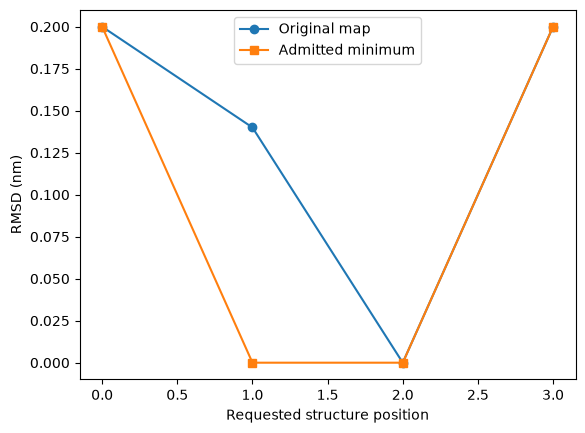

In [1]:
import molsysmt as msm
import numpy as np
from rdkit import Chem
import matplotlib.pyplot as plt

molsys = msm.convert(Chem.MolFromSmiles('c1ccccc1'), to_form='molsysmt.MolSys')
phase = np.arange(6) * np.pi / 3
reference_coordinates = 0.14 * np.column_stack((np.cos(phase), np.sin(phase), np.zeros(6)))
coordinates = np.array([reference_coordinates, reference_coordinates[[1, 2, 3, 4, 5, 0]], reference_coordinates + [0, 0, 0.2]])
molsys.structures.append(coordinates=msm.pyunitwizard.quantity(coordinates, 'nm'))
baseline = np.column_stack((np.arange(6), np.arange(6)))
result = msm.structure.get_symmetry_corrected_rmsd(molsys, structure_indices=[2, 1, 0, 2], baseline_atom_correspondence=baseline)
corrected = msm.pyunitwizard.get_value(result['rmsd'], to_unit='nm')
raw = msm.pyunitwizard.get_value(result['raw_rmsd'], to_unit='nm')
np.testing.assert_allclose(corrected, [0.2, 0, 0, 0.2], atol=1e-14)
print('Requested structure indices:', result['structure_indices'])
print('Corrected RMSD (nm):', corrected)
print('Original positional RMSD (nm):', raw)
fig, ax = plt.subplots()
ax.plot(range(4), raw, 'o-', label='Original map')
ax.plot(range(4), corrected, 's-', label='Admitted minimum')
ax.set(xlabel='Requested structure position', ylabel='RMSD (nm)')
ax.legend()
plt.show()

## Inspecting the chosen map

`correspondence_indices` selects one row of a shared map table for each requested structure. This avoids copying a complete map per structure. Exact ties choose the lexical first map; `n_near_optimal_correspondences` counts candidates within the absolute length `tie_tolerance`. Near ties do not replace the actual minimum.

In [2]:
maps = result['correspondences']['atom_correspondences']
chosen = maps[result['correspondence_indices'][1]]
print('Map for requested structure 1:', chosen)
print('Near-optimal mapping counts:', result['n_near_optimal_correspondences'])

Map for requested structure 1: [[0 1]
 [1 2]
 [2 3]
 [3 4]
 [4 5]
 [5 0]]
Near-optimal mapping counts: [1 1 1 1]


## Reusing maps and changing units

Coordinates can change while their chemical correspondences remain valid. Reuse checks the current graphs, populations and axes without enumerating them again. Chemical edits, extraction/reordering and changed selections require fresh maps. Input quantities are converted to nm for computation; results follow your active length-unit policy.

In [3]:
cached = result['correspondences']
with msm.pyunitwizard.context(standard_units=['angstrom', 'ps']):
    repeated = msm.structure.get_symmetry_corrected_rmsd(molsys, correspondences=cached, structure_indices=[2], tie_tolerance='0.01 angstrom')
    print('Corrected RMSD:', repeated['rmsd'])
    np.testing.assert_allclose(msm.pyunitwizard.get_value(repeated['rmsd']), [2.0])

Corrected RMSD: [2.0] angstrom


## Restricting the corrected correspondence

A baseline map defines `raw_rmsd` and does not constrain the corrected search. Use `fixed_atom_correspondence` to impose partial chemical anchors, or `candidate_atom_correspondences` to evaluate only complete selected-population maps you propose. These two options can be combined when they agree. Every candidate must have a valid whole-component chemical extension.

The unrestricted ring permutation has zero corrected RMSD. Anchoring two adjacent atoms to their original indices leaves the identity map, so that same pose has a nonzero **conditional** minimum. Never interpret this as the unrestricted symmetry minimum.


In [4]:
anchored = msm.structure.get_symmetry_corrected_rmsd(
    molsys, structure_indices=[1], fixed_atom_correspondence=[[0, 0], [1, 1]])
proposed = msm.structure.get_symmetry_corrected_rmsd(
    molsys, structure_indices=[1], candidate_atom_correspondences=baseline)
np.testing.assert_allclose(msm.pyunitwizard.get_value(anchored['rmsd'], to_unit='nm'), [0.14])
np.testing.assert_allclose(msm.pyunitwizard.get_value(proposed['rmsd'], to_unit='nm'), [0.14])
print('Anchored:', anchored['rmsd'], anchored['search_scope'])
print('Supplied:', proposed['rmsd'], proposed['search_scope'])
reused = msm.structure.get_symmetry_corrected_rmsd(
    molsys, structure_indices=[1], correspondences=proposed['correspondences'])
assert reused['search_scope'] == 'supplied_atom_correspondences'


Anchored: [0.14] nanometer anchored_chemical_correspondences
Supplied: [0.14] nanometer supplied_atom_correspondences


## Comparing a ligand group from a protein structure

The bundled 181L structure provides a benzene pose. Here you explicitly declare its graph independently and verify the coordinate atom order. No chemical assignment is inferred from the point set. `parent_indices` maps this local six-atom system back to the original protein system.

In [5]:
source = msm.systems['T4 lysozyme L99A']['181l.pdb']
parent_indices = np.asarray(msm.select(source, selection="group_name=='BNZ'"))
assert msm.get(source, selection=parent_indices, atom_name=True) == ['C1', 'C2', 'C3', 'C4', 'C5', 'C6']
molsys = msm.convert(Chem.MolFromSmiles('c1ccccc1'), to_form='molsysmt.MolSys')
molsys.structures.append(coordinates=msm.get(source, selection=parent_indices, coordinates=True))
pose = msm.structure.get_symmetry_corrected_rmsd(molsys)
print('Parent atom indices:', parent_indices)
print('Self-reference pose RMSD:', pose['rmsd'])

Parent atom indices: [1299 1300 1301 1302 1303 1304]
Self-reference pose RMSD: [0.0] nanometer


## Handling large inputs and unsupported chemistry

`heavy_mode='force'` streams eligible native/H5MSM coordinate sources; `'off'` uses bounded eager delivery. `max_matches` controls chemical enumeration. Complete output and map tables remain resident. Numeric budgets do not bound all process RSS or matching time. Empty structure lists retain empty quantities/index arrays; an empty atom population is invalid.

Raw RMSD requires an explicitly declared baseline; otherwise `raw_rmsd` is `None`. Equal counts and IDs do not establish correspondence. If a baseline violates the chemical admission policy, corrected RMSD is not guaranteed to be smaller. Reference states must be compatible: a neutral CCD reference and a protonated simulation graph are not automatically equivalent.

Potential unassigned stereo, incomplete chemistry and incompatible state constraints fail explicitly. Periodic molecules must be reconstructed explicitly with general PBC tools before comparison. Correspondence/geometry dictionaries do not create a new native H5MSM result domain.

## Understanding scientific provenance

The graph-minimum approach is inspired by [Bell and Zhang (2019)](https://doi.org/10.1186/s13321-019-0362-7) and [Meli and Biggin (2020)](https://doi.org/10.1186/s13321-020-00455-2). MolSysMT uses its own stricter state policy, RDKit graph matching and bundled Rust positional RMSD. Neither cited program is executed or reproduced faithfully. Original software versions and bibliography accompany each result; optional Ackredit retains contextual inspiration/execution roles.

:::{seealso}
:class: dropdown
{ref}`Tutorial_Get_atom_correspondences` defines chemical admission. {func}`molsysmt.structure.get_rmsd` computes positional RMSD; {func}`molsysmt.structure.get_least_rmsd` performs superposition. {ref}`Cookbook_SymmetryPoseRMSD` gives the evaluation workflow.
:::

When assigned stereo labels are used, RDKit executes the [Hanson et al. (2018) CIP algorithm](https://doi.org/10.1021/acs.jcim.8b00324). This reused scientific criterion is recorded separately from the inspiration for pose RMSD.

The initial profile requires the same indexed-H representation and H policy on both sides, even when the metric excludes H. Bring both sources to a common declared representation explicitly before comparison.
